<center><h1>Leonez_Teresa_HW3</h1></center>
<br>
<br>

Name: Teresa Leonez
<br>
Github Username: ttl229
<br>
USC ID:  9630346635

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [1]:
import pandas as pd
from pathlib import Path
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Set column names as global variable
column_names = ['time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23'
               ]

# Function to load dataset for multiple dataset loading
def load_instance(filepath):
    df = pd.read_csv(filepath, comment ='#', header=None, names=column_names, sep=r'[,\s]+', engine='python')
    return df

# Function to get time-domain features for one dataset
def get_features(df)-> features:
    sensors = df.drop(columns='time')  # Drop the time column 
    stats = {
        'min': sensors.min(),         # Gets mean from data
        'max': sensors.max(),         # Gets max from data
        'median': sensors.median(),   # Gets median from data
        'mean': sensors.mean(),       # Gets mean 
        'sd': sensors.std(),          # Gets standard deviation data
        'q1': sensors.quantile(.25),  # Gets Q1 data
        'q3': sensors.quantile(.75),  # Gets Q3 data
    }

    features = {}  # sets up dictionary to store features for all datasets
    for stat_name, values in stats.items():
        for i, value in enumerate (values, start=1): 
            features[f'{stat_name}_{i}'] = value
    return features

# Function to split files into test and training data
def is_test(folder, n):
    if folder.startswith("bending"):  # if dataset is in bending1 and bending2 
        return n <= 2                 # pull dataset1 and dataset2 from bending1 and bending2
    return n <= 3      # pull dataset1, dataset2, dataset3, from all other folders


# Function for Python Bootstrapped resampling (Question iii.)
def bootstrap_column_std(column, n_bootstrap=1000, alpha=.10):   
    """ Takes parameters of column name, n for bootstrap with default 1000 """
    lower_percentile = 100* (alpha/2)  # 
    upper_percentile = 100* (1-(alpha/2))
    bootstrap_stds = [] # Holds the bootstrap standard deviations
    # bootstrap calculation 
    column_length = len(column)
    for i in range(n_bootstrap): # Repeat n number of times
        sample_result = column.sample(n=column_length, frac=None, replace=True, random_state=i) # Get sample
        sample_std = sample_result.std()
        bootstrap_stds.append(sample_std) # Store sample std in bootstrap stds list
    return np.percentile(bootstrap_stds, [lower_percentile, upper_percentile]) 
    """  Returns stds as list, upper and lower percentile """

def relabel_sensors(feature): 
    stat, series = feature.split('_')          # split the 'min_1' to min, 1
    return f"{stat} | {series_names[series]}"  # relabels the output data for easier comprehension

Get the AReM Data Set

In [3]:
# Test that data is loading with function correctly
df = load_instance("AReM/bending1/dataset4.csv")

In [4]:
# Test get_features function is working correctly
len(get_features(df))

# Test the is_test function works properly
is_test("bending1", 1)

True

### (b) Test and Train Data

In [5]:
# Set file names as list to extract features into new dataframe
dataset_files = sorted(Path("AReM").glob("*/*.csv"))

### (c) Feature Extraction

#### i. Research

Some of the more common time-domain features used in time series classification include:
1. Measurements of central tendencies such as mean, median, mode
2. Measurements of skewness and direction of skewness (kurtosis and tail shape), effect and presence of outliers
3. Root mean square (RMS) measures energy and magnitude
4. Temporal dependencies such as Lag features (raw or transformed values at specific time steps), auto-correlation, cross-correlation, and partial autocorrelation
5. Entropy measures irregularity and unpredictability of sequence

#### ii. Extraction

In [6]:
rows = []
for filepath in dataset_files:   # Loop through the dataset files to load features to a list
    activity = filepath.parent.name # adjusts name of file to include activity marker
    n = int(filepath.stem.replace('dataset', ''))
    
    df = load_instance(filepath)
    features = get_features(df)
    features['activity'] = activity
    features['n']=n
    features['split'] = 'test' if is_test(activity, n) else 'train' # Splits files into test and train data
    rows.append(features)

features_df = pd.DataFrame(rows) # Feed list of features into cleaned dataframe
print(features_df)

feature_columns = features_df.columns.drop(['activity', 'n', 'split']) # Drops the non data columns for std calculation

    min_1  min_2  min_3  min_4  min_5  min_6  max_1  max_2  max_3  max_4  ...  \
0   37.25    0.0   4.00    0.0  27.25    0.0  45.00   1.30  29.50   7.23  ...   
1   38.00    0.0   2.00    0.0  27.67    0.0  45.67   1.22  29.50   5.76  ...   
2   35.00    0.0   6.50    0.0  29.00    0.0  47.40   1.70  29.75   4.44  ...   
3   33.00    0.0   8.50    0.0  20.00    0.0  47.75   3.00  30.00   5.15  ...   
4   33.00    0.0   3.00    0.0  23.67    0.0  45.75   2.83  28.25   6.42  ...   
..    ...    ...    ...    ...    ...    ...    ...    ...    ...    ...  ...   
83  20.75    0.0   5.00    0.0   6.00    0.0  46.25  12.68  23.75   9.20  ...   
84  21.50    0.0   6.50    0.0   6.33    0.0  51.00  12.21  23.33   9.09  ...   
85  18.33    0.0   7.67    0.0   6.67    0.0  47.67  12.48  23.33   9.01  ...   
86  18.33    0.0   5.50    0.0   6.50    0.0  45.75  15.37  24.00   9.18  ...   
87  15.50    0.0   7.67    0.0   5.75    0.0  43.67  17.24  23.00   9.20  ...   

    q1_6     q3_1    q3_2  

#### iii. Standard Deviation

In [7]:
#  Estimate the standard deviation of each of the time-domain features extracted from data
features_std = features_df[feature_columns].std()

print(len(features_std)) # Check results

42


In [8]:
#build a CI=90% bootsrap confidence interval for the standard deviation of each feature
results = {} 
for column in feature_columns:
    lower, upper = bootstrap_column_std(features_df[column])
    results[column] = {'std': features_std[column], 'ci_lower': lower, 'ci_upper': upper}

ci_df = pd.DataFrame(results).T
""" stores results of bootstrapped confidence interval into a dataframe """

' stores results of bootstrapped confidence interval into a dataframe '

In [9]:
# Verify standard deviations are within upper and lower bound
def std_in_range(std, lower, upper):
    return lower <= std <= upper

for feature, row in ci_df.iterrows():
    print(feature, std_in_range(row['std'], row['ci_lower'], row['ci_upper']))

min_1 True
min_2 True
min_3 True
min_4 True
min_5 True
min_6 True
max_1 True
max_2 True
max_3 True
max_4 True
max_5 True
max_6 True
median_1 True
median_2 True
median_3 True
median_4 True
median_5 True
median_6 True
mean_1 True
mean_2 True
mean_3 True
mean_4 True
mean_5 True
mean_6 True
sd_1 True
sd_2 True
sd_3 True
sd_4 True
sd_5 True
sd_6 True
q1_1 True
q1_2 True
q1_3 True
q1_4 True
q1_5 True
q1_6 True
q3_1 True
q3_2 True
q3_3 True
q3_4 True
q3_5 True
q3_6 True


In [10]:
print(ci_df)

               std  ci_lower   ci_upper
min_1     9.569975  8.241837  10.759550
min_2     0.000000  0.000000   0.000000
min_3     2.956462  2.755207   3.121526
min_4     0.000000  0.000000   0.000000
min_5     6.124001  4.446002   7.479130
min_6     0.045838  0.000000   0.078476
max_1     4.394362  3.347796   5.305053
max_2     5.062729  4.635156   5.418794
max_3     4.875137  4.131827   5.450162
max_4     2.183625  1.971891   2.350989
max_5     5.741238  4.761321   6.599242
max_6     2.518921  2.267148   2.748453
median_1  5.440054  4.798265   6.005214
median_2  1.412244  1.238122   1.553404
median_3  4.036396  3.420191   4.539670
median_4  1.145586  1.057360   1.201524
median_5  5.813782  4.439108   6.908353
median_6  1.086474  0.996648   1.149553
mean_1    5.335718  4.718218   5.886207
mean_2    1.574164  1.396469   1.713572
mean_3    4.008380  3.391225   4.499933
mean_4    1.166114  1.078930   1.221913
mean_5    5.675593  4.371010   6.724168
mean_6    1.154812  1.061909   1.213707


In [11]:
# Relabel the features in the output graph for comprehension
series_names = {
    '1': 'chest to ankle 1 avg', '2': 'chest to ankle 1 variance',
    '3': 'chest to ankle 2 avg', '4': 'chest to ankle 2 variance',
    '5': 'ankle 1 to ankle 2 avg', '6': 'ankle 1 to ankle 2 var',
}

#### iv. Select Features

In [12]:
# View features data with activity labeled to compare
grouped_df = features_df.groupby('activity')[feature_columns].mean().T
""" group by activity and flip reverse for easier reading """

grouped_df

activity,bending1,bending2,cycling,lying,sitting,standing,walking
min_1,35.642857,17.541667,24.377333,33.216667,35.544667,34.744000,18.816000
min_2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
min_3,4.464286,1.583333,5.733333,0.066667,1.044667,2.366667,6.267333
min_4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
min_5,20.988571,4.723333,5.484000,0.466667,2.216667,1.233333,6.350000
min_6,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.028667
max_1,46.795714,44.958333,44.483333,42.733333,46.356000,47.120000,46.261333
max_2,1.875714,6.385000,10.849333,2.444667,3.277333,2.900667,14.000667
max_3,28.618571,27.360000,26.389333,14.715333,23.531333,21.316667,23.572000
max_4,6.314286,6.850000,9.218667,4.196000,5.925333,5.584667,9.054667


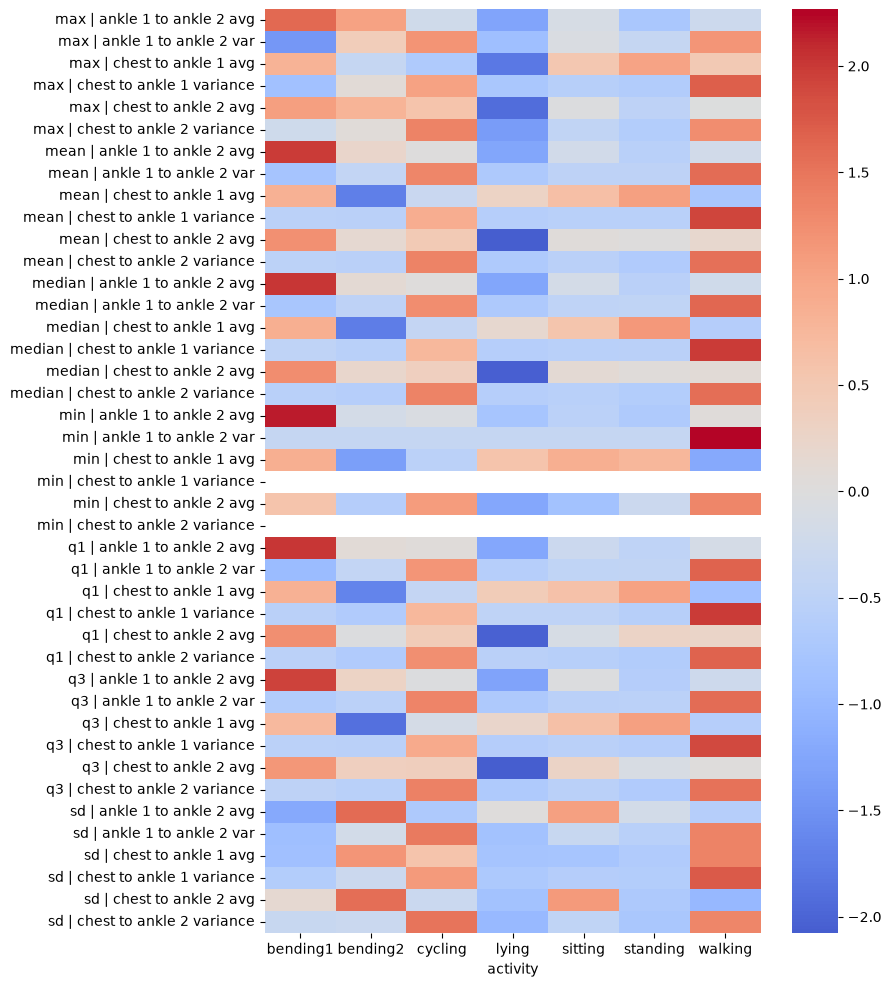

In [16]:
# Scale each row for comparability in graphed display
scaled_grouped_df = grouped_df.sub(grouped_df.mean(axis=1), axis=0).div(grouped_df.std(axis=1), axis=0)
readable_df = scaled_grouped_df.rename(index=relabel_sensors)
readable_df = readable_df.sort_index()

# Plot scaled grouped df
plt.figure(figsize=(8,12))
sns.heatmap(readable_df, cmap='coolwarm', center=0) # Plot using heattmap to visualize feature variance data
plt.show()

Answer: I chose to use time-domain features max, mean, and standard deviation because they show dynamic contrast between the activities and each provide insight to the data in a different form. While minimum overall has high variance, it's missing an entire dataset (min_2) and therefore I chose to ignore it and use maximum instead, which shows the peaks of motion. Mean is a great indicator of an overall baseline and shows posture such as lying vs standing. The standard deviation shows how much the signal moves between different activities.

## 2. ISLR 3.7.4

### (a) Linear Train

### (b) Linear Test

### (c) Not Linear Train

### (d) Not Linear Testing

## 3. ISLR 3.7.3 - Extra Practice 

## 3. ISLR 3.7.5 - Extra Practice 